# 수도권 마이크로허브 분석

> 팀민지

## 사전) 데이터셋 다운로드받기
구글 드라이브 링크 https://drive.google.com/drive/folders/1rsCFvmAy9UypAo5vkiXk1YDpBWZq7I26?usp=drive_link 혹은

- 우체국 우편주소 DB: [우체국 우편주소 DB 다운로드](https://www.epost.go.kr/search/zipcode/areacdAddressDown.jsp)에서 `지역별 주소 DB` 다운로드 후 압축 해제
- 우체국 전국 물동량 데이터: [공공데이터포털](https://www.data.go.kr/data/15138728/fileData.do?recommendDataYn=Y) 다운로드 파일 사용
- CJ 전국 -> 서울 물동량 데이터: [서울 열린 데이터광장](https://data.seoul.go.kr/dataList/OA-21865/S/1/datasetView.do#) 전체 파일 보기 클릭 후 모든 데이터셋 저장하여 cj_data 폴더로 취합

> 파일 형태

├── 과학기술정보통신부 우정사업본부_전국 우편번호(배달지 기준)별 택배물량_20231231.csv  
├── cj_data  
│   ├── DWC_KXLCLS_OD_DAY_SIDO_SEOULGU_202301.csv  
│   ├── DWC_KXLCLS_OD_DAY_SIDO_SEOULGU_202302.csv  
│   ├── DWC_KXLCLS_OD_DAY_SIDO_SEOULGU_202303.csv  
│   ├── ...  
│   └── DWC_KXLCLS_OD_DAY_SIDO_SEOULGU_202312.csv  
│ 
├── 수도권_마이크로허브_분석.ipynb  
├── zipcode_DB  
│   ├── 서울특별시txt  
│   ├── 경기도.txt   
│   └── 인천광역시.txt  

## 0. 설정

In [1]:
from pathlib import Path
from math import radians, sin, cos, sqrt, atan2
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display
from scipy import stats
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

def set_korean_font():
    font_paths = [
        Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),
        Path("/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf"),
    ]

    for font_path in font_paths:
        if font_path.exists():
            fm.fontManager.addfont(str(font_path))
            plt.rcParams["font.family"] = "NanumGothic"
            break

    if platform.system() == "Darwin":
        plt.rcParams["font.family"] = "AppleGothic"

    plt.rcParams["axes.unicode_minus"] = False

set_korean_font()

In [2]:
BASE_DIR = Path(".")
ZIPCODE_DIR = BASE_DIR / "zipcode_DB"
CJ_DIR = BASE_DIR / "cj_data"
POST_PATH = BASE_DIR / "과학기술정보통신부 우정사업본부_전국 우편번호(배달지 기준)별 택배물량_20231231.csv"
OUTPUT_DIR = BASE_DIR / "paradox_result"

YEAR = 2023
SAVE_OUTPUTS = False
TARGET_SIDOS = ("서울특별시", "경기도", "인천광역시")
METRO_ORIGINS = list(TARGET_SIDOS)
K_RANGE = range(10, 16)
K_SELECTED = 13
RANDOM_SEED = 42
ZIPCODE_MAPPING_PATH = BASE_DIR / "zipcode_sigungu_mapping.csv"

In [3]:
def ensure_output_dir():
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def save_table(df, filename, **kwargs):
    if not SAVE_OUTPUTS:
        return

    ensure_output_dir()
    path = OUTPUT_DIR / filename

    if path.suffix == ".xlsx":
        df.to_excel(path, index=False, **kwargs)
    elif path.suffix == ".csv":
        df.to_csv(path, index=False, encoding="utf-8-sig", **kwargs)
    else:
        raise ValueError(f"지원하지 않는 확장자입니다: {path.suffix}")

def save_figure(fig, filename):
    if SAVE_OUTPUTS:
        ensure_output_dir()
        fig.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")

## 1. 데이터 로드와 보간

In [4]:
def load_zipcode_mapping(zipcode_dir):
    rows = []

    for path in sorted(zipcode_dir.glob("*.txt")):
        with path.open("r", encoding="utf-8") as file:
            next(file, None)

            for line in file:
                parts = line.rstrip("\n").split("|")

                if len(parts) < 4:
                    continue

                zipcode = parts[0].strip().zfill(5)
                sido = parts[1].strip()
                sigungu = parts[3].strip()

                if sido in TARGET_SIDOS and zipcode and sigungu:
                    rows.append((zipcode, sido, sigungu))

    if rows:
        mapping = pd.DataFrame(rows, columns=["zipcode", "sido", "sigungu"])
    elif ZIPCODE_MAPPING_PATH.exists():
        mapping = pd.read_csv(ZIPCODE_MAPPING_PATH, dtype=str)
    else:
        raise FileNotFoundError(f"수도권 우편번호 데이터를 찾지 못했습니다: {zipcode_dir}")

    mapping["zipcode"] = mapping["zipcode"].astype(str).str.strip().str.zfill(5)
    mapping["sido"] = mapping["sido"].astype(str).str.strip()
    mapping["sigungu"] = mapping["sigungu"].astype(str).str.strip()

    return (
        mapping[["zipcode", "sido", "sigungu"]]
        .drop_duplicates()
        .reset_index(drop=True)
    )

def load_post_data(path):
    df = pd.read_csv(path, encoding="cp949", header=None, skiprows=1)
    month_cols = list(map(str, range(1, df.shape[1])))
    df.columns = ["zipcode", *month_cols]
    df["zipcode"] = df["zipcode"].astype(str).str.strip().str.zfill(5)
    df[month_cols] = df[month_cols].apply(pd.to_numeric, errors="coerce").fillna(0).astype("int64")
    return df

def month_columns(df):
    return sorted([column for column in df.columns if str(column).isdigit()], key=lambda x: int(x))

def classify_post_region(post_df):
    df = post_df.copy()
    prefix = df["zipcode"].str[:2]

    df["region"] = np.select(
        [
            prefix.between("01", "09"),
            prefix.between("10", "18"),
            prefix.between("21", "23"),
            prefix.between("24", "99"),
        ],
        ["서울", "경기", "인천", "비수도권"],
        default=None,
    )

    return df[df["region"].notna()].copy()

def build_monthly_post(post_df):
    region_df = classify_post_region(post_df)
    months = month_columns(region_df)

    long_df = region_df.melt(
        id_vars=["zipcode", "region"],
        value_vars=months,
        var_name="month",
        value_name="volume",
    )

    long_df["month"] = long_df["month"].astype(int)

    pivot = (
        long_df
        .groupby(["month", "region"], as_index=False)["volume"]
        .sum()
        .pivot(index="month", columns="region", values="volume")
        .fillna(0)
        .reset_index()
    )

    for region in ["서울", "경기", "인천", "비수도권"]:
        if region not in pivot:
            pivot[region] = 0

    monthly = pd.DataFrame(
        {
            "month": pivot["month"].astype(int),
            "post_seoul": pivot["서울"].astype("int64"),
            "post_gyeonggi": pivot["경기"].astype("int64"),
            "post_incheon": pivot["인천"].astype("int64"),
        }
    )

    monthly["post_metro"] = monthly[["post_seoul", "post_gyeonggi", "post_incheon"]].sum(axis=1)
    monthly["whole_post"] = pivot[["서울", "경기", "인천", "비수도권"]].sum(axis=1).astype("int64")
    monthly["scale_metro_to_seoul"] = monthly["post_metro"] / monthly["post_seoul"]
    monthly["scale_gyeonggi_to_seoul"] = monthly["post_gyeonggi"] / monthly["post_seoul"]
    monthly["scale_incheon_to_seoul"] = monthly["post_incheon"] / monthly["post_seoul"]
    monthly["post_metro_share_of_total"] = monthly["post_metro"] / monthly["whole_post"]

    return monthly.sort_values("month").reset_index(drop=True)

def cj_files(cj_dir, year):
    files = {
        path
        for pattern in ("*.csv", "*.CSV")
        for path in cj_dir.glob(pattern)
        if f"_{year}" in path.name
    }

    return sorted(files)

def load_cj_data(cj_dir, year):
    frames = []

    for path in cj_files(cj_dir, year):
        df = pd.read_csv(path, encoding="cp949")
        volume_cols = [column for column in df.columns if "대분류_착지물동량" in column]

        if not volume_cols:
            continue

        use = pd.DataFrame(
            {
                "month": pd.to_datetime(df["배송년월일"].astype(str), format="%Y%m%d").dt.month.astype(int),
                "origin_sido": df["송하인_시명"],
                "dest_sido": df["수하인_시명"],
                "dest_gu": df["수하인_구명"],
                "volume": (
                    df[volume_cols]
                    .apply(pd.to_numeric, errors="coerce")
                    .fillna(0)
                    .sum(axis=1)
                    .astype("int64")
                ),
            }
        )

        frames.append(use)

    if not frames:
        raise FileNotFoundError(f"CJ {year}년 CSV 데이터를 찾지 못했습니다: {cj_dir}")

    return pd.concat(frames, ignore_index=True)

def build_monthly_cj(cj_df):
    total = (
        cj_df
        .groupby("month", as_index=False)["volume"]
        .sum()
        .rename(columns={"volume": "cj_to_seoul_observed"})
    )

    nonmetro = (
        cj_df[~cj_df["origin_sido"].isin(METRO_ORIGINS)]
        .groupby("month", as_index=False)["volume"]
        .sum()
        .rename(columns={"volume": "cj_nonmetro_to_seoul_observed"})
    )

    metro = (
        cj_df[cj_df["origin_sido"].isin(METRO_ORIGINS)]
        .groupby("month", as_index=False)["volume"]
        .sum()
        .rename(columns={"volume": "cj_metro_origin_to_seoul_observed"})
    )

    return (
        total
        .merge(nonmetro, on="month", how="left")
        .merge(metro, on="month", how="left")
        .fillna(0)
        .sort_values("month")
        .reset_index(drop=True)
    )

def build_monthly_estimates(monthly_post, monthly_cj):
    monthly = monthly_post.merge(monthly_cj, on="month", how="inner").sort_values("month").reset_index(drop=True)

    monthly["est_cj_all_origins_to_metro"] = (
        monthly["cj_to_seoul_observed"] * monthly["scale_metro_to_seoul"]
    ).round().astype("int64")

    monthly["est_cj_nonmetro_to_metro"] = (
        monthly["cj_nonmetro_to_seoul_observed"] * monthly["scale_metro_to_seoul"]
    ).round().astype("int64")

    monthly["est_cj_metro_origin_to_metro"] = (
        monthly["cj_metro_origin_to_seoul_observed"] * monthly["scale_metro_to_seoul"]
    ).round().astype("int64")

    monthly["cj_nonmetro_share_to_seoul"] = (
        monthly["cj_nonmetro_to_seoul_observed"] / monthly["cj_to_seoul_observed"]
    )

    return monthly

def build_summary(monthly):
    summary = pd.DataFrame(
        {
            "metric": [
                "우체국 서울 도착 물량",
                "우체국 경기 도착 물량",
                "우체국 인천 도착 물량",
                "우체국 수도권 도착 물량",
                "우체국 전국 도착 물량",
                "CJ 전국→서울 관측 물동량",
                "CJ 비수도권→서울 관측 물동량",
                "추정 CJ 전국→수도권 물동량, 수도권 출발 포함",
                "추정 CJ 비수도권→수도권 유입 물동량",
            ],
            "value": [
                monthly["post_seoul"].sum(),
                monthly["post_gyeonggi"].sum(),
                monthly["post_incheon"].sum(),
                monthly["post_metro"].sum(),
                monthly["whole_post"].sum(),
                monthly["cj_to_seoul_observed"].sum(),
                monthly["cj_nonmetro_to_seoul_observed"].sum(),
                monthly["est_cj_all_origins_to_metro"].sum(),
                monthly["est_cj_nonmetro_to_metro"].sum(),
            ],
        }
    )

    summary["value"] = summary["value"].astype("int64")
    return summary

In [5]:
def fisher_ci(r, n, alpha=0.05):
    if n <= 3 or np.isnan(r) or abs(r) >= 1:
        return np.nan, np.nan

    z = np.arctanh(r)
    se = 1 / np.sqrt(n - 3)
    zcrit = stats.norm.ppf(1 - alpha / 2)

    return np.tanh(z - zcrit * se), np.tanh(z + zcrit * se)

def corr_summary(df, x_col, y_col, label):
    data = df[[x_col, y_col]].dropna()
    x = data[x_col].astype(float).to_numpy()
    y = data[y_col].astype(float).to_numpy()
    n = len(data)

    pearson_r, pearson_p = stats.pearsonr(x, y)
    spearman_rho, spearman_p = stats.spearmanr(x, y)
    kendall_tau, kendall_p = stats.kendalltau(x, y)
    ci_low, ci_high = fisher_ci(pearson_r, n)

    log_r, log_p = stats.pearsonr(np.log1p(x), np.log1p(y))
    log_ci_low, log_ci_high = fisher_ci(log_r, n)

    diff_r, diff_p = stats.pearsonr(np.diff(x), np.diff(y))
    diff_ci_low, diff_ci_high = fisher_ci(diff_r, n - 1)

    t = np.arange(n)
    x_resid = x - np.polyval(np.polyfit(t, x, 1), t)
    y_resid = y - np.polyval(np.polyfit(t, y, 1), t)
    detrended_r, detrended_p = stats.pearsonr(x_resid, y_resid)
    detrended_ci_low, detrended_ci_high = fisher_ci(detrended_r, n)

    return {
        "pair": label,
        "x": x_col,
        "y": y_col,
        "n": n,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "pearson_ci95_low": ci_low,
        "pearson_ci95_high": ci_high,
        "spearman_rho": spearman_rho,
        "spearman_p": spearman_p,
        "kendall_tau": kendall_tau,
        "kendall_p": kendall_p,
        "log_pearson_r": log_r,
        "log_pearson_p": log_p,
        "log_ci95_low": log_ci_low,
        "log_ci95_high": log_ci_high,
        "diff_pearson_r": diff_r,
        "diff_pearson_p": diff_p,
        "diff_ci95_low": diff_ci_low,
        "diff_ci95_high": diff_ci_high,
        "detrended_pearson_r": detrended_r,
        "detrended_pearson_p": detrended_p,
        "detrended_ci95_low": detrended_ci_low,
        "detrended_ci95_high": detrended_ci_high,
    }

def build_monthly_validation(monthly):
    validation = monthly.sort_values("month").reset_index(drop=True).copy()
    validation["est_cj_to_metro"] = validation["cj_to_seoul_observed"] * validation["scale_metro_to_seoul"]
    validation["est_cj_nonmetro_to_metro"] = (
        validation["cj_nonmetro_to_seoul_observed"] * validation["scale_metro_to_seoul"]
    )

    if len(validation) != 12:
        raise ValueError(f"월별 데이터가 12개월이 아닙니다: {len(validation)}")

    if validation["month"].tolist() != list(range(1, 13)):
        raise ValueError(f"월별 데이터가 1~12월 순서가 아닙니다: {validation['month'].tolist()}")

    return validation

def build_correlation_metrics(monthly_validation):
    pairs = [
        ("post_seoul", "cj_to_seoul_observed", "우체국 서울 도착량 vs CJ 전국→서울 유입량"),
        ("post_seoul", "cj_nonmetro_to_seoul_observed", "우체국 서울 도착량 vs CJ 비수도권→서울 유입량"),
        ("post_metro", "est_cj_to_metro", "우체국 수도권 도착량 vs 추정 CJ 전국→수도권 유입량"),
        ("post_metro", "est_cj_nonmetro_to_metro", "우체국 수도권 도착량 vs 추정 CJ 비수도권→수도권 유입량"),
    ]

    return pd.DataFrame(
        [corr_summary(monthly_validation, x_col, y_col, label) for x_col, y_col, label in pairs]
    )

In [6]:
def build_origin_month(cj_df, monthly):
    origin_month = (
        cj_df
        .groupby(["month", "origin_sido"], as_index=False)["volume"]
        .sum()
        .rename(columns={"volume": "cj_to_seoul_observed"})
        .merge(
            monthly[["month", "scale_gyeonggi_to_seoul", "scale_incheon_to_seoul", "scale_metro_to_seoul"]],
            on="month",
            how="left",
        )
    )

    origin_month["est_to_seoul"] = origin_month["cj_to_seoul_observed"]
    origin_month["est_to_gyeonggi"] = (
        origin_month["cj_to_seoul_observed"] * origin_month["scale_gyeonggi_to_seoul"]
    ).round().astype("int64")
    origin_month["est_to_incheon"] = (
        origin_month["cj_to_seoul_observed"] * origin_month["scale_incheon_to_seoul"]
    ).round().astype("int64")
    origin_month["est_to_metro_total"] = origin_month[["est_to_seoul", "est_to_gyeonggi", "est_to_incheon"]].sum(axis=1)
    origin_month["origin_group"] = np.where(
        origin_month["origin_sido"].isin(METRO_ORIGINS),
        "수도권 출발",
        "비수도권 출발",
    )

    return origin_month

def build_annual_by_origin(origin_month):
    annual = (
        origin_month
        .groupby(["origin_sido", "origin_group"], as_index=False)[
            ["cj_to_seoul_observed", "est_to_gyeonggi", "est_to_incheon", "est_to_metro_total"]
        ]
        .sum()
        .sort_values("est_to_metro_total", ascending=False)
        .reset_index(drop=True)
    )

    annual["metro_total_share"] = annual["est_to_metro_total"] / annual["est_to_metro_total"].sum()

    nonmetro = annual[annual["origin_group"].eq("비수도권 출발")].copy()
    nonmetro["metro_total_share_nonmetro_only"] = (
        nonmetro["est_to_metro_total"] / nonmetro["est_to_metro_total"].sum()
    )

    return annual, nonmetro

def build_sigungu_shares(post_df, zipcode_mapping):
    months = month_columns(post_df)

    post_for_sigungu = (
        post_df[["zipcode", *months]]
        .merge(zipcode_mapping, on="zipcode", how="left")
        .dropna(subset=["sido", "sigungu"])
        .copy()
    )

    long_df = post_for_sigungu.melt(
        id_vars=["zipcode", "sido", "sigungu"],
        value_vars=months,
        var_name="month",
        value_name="post_volume",
    )

    long_df["month"] = long_df["month"].astype(int)
    long_df["post_volume"] = long_df["post_volume"].astype("int64")

    monthly = (
        long_df
        .groupby(["month", "sido", "sigungu"], as_index=False)["post_volume"]
        .sum()
    )

    monthly["region_total"] = monthly.groupby(["month", "sido"])["post_volume"].transform("sum")
    monthly["sigungu_share"] = monthly["post_volume"] / monthly["region_total"]

    shares = monthly[["month", "sido", "sigungu", "sigungu_share"]].copy()
    return shares[shares["sido"].eq("경기도")].copy(), shares[shares["sido"].eq("인천광역시")].copy()

def build_seoul_gu_flow(cj_df):
    flow = (
        cj_df[cj_df["origin_sido"].isin(METRO_ORIGINS)]
        .groupby(["month", "origin_sido", "dest_sido", "dest_gu"], as_index=False)["volume"]
        .sum()
    )

    result = pd.DataFrame(
        {
            "출발지": flow["origin_sido"],
            "도착지": flow["dest_sido"] + " " + flow["dest_gu"],
            "물동량": flow["volume"].round().astype("int64"),
            "month_order": flow["month"].astype(int),
        }
    )

    result["달"] = result["month_order"].map(lambda month: f"{YEAR}년 {month}월")
    return result[["출발지", "도착지", "물동량", "달", "month_order"]].copy()

def distribute_origin_to_sigungu(metro_origin_base, target_col, share_df):
    distributed = (
        metro_origin_base[["month", "origin_sido", target_col]]
        .merge(share_df, on="month", how="left")
        .dropna(subset=["sigungu_share"])
        .copy()
    )

    distributed["출발지"] = distributed["origin_sido"]
    distributed["도착지"] = distributed["sido"] + " " + distributed["sigungu"]
    distributed["물동량"] = (distributed[target_col] * distributed["sigungu_share"]).round().astype("int64")
    distributed["month_order"] = distributed["month"].astype(int)
    distributed["달"] = distributed["month_order"].map(lambda month: f"{YEAR}년 {month}월")

    return distributed[["출발지", "도착지", "물동량", "달", "month_order"]].copy()

def build_sigungu_flow(cj_df, origin_month, gyeonggi_share, incheon_share):
    metro_origin_base = origin_month[origin_month["origin_sido"].isin(METRO_ORIGINS)].copy()
    metro_origin_base["month"] = metro_origin_base["month"].astype(int)

    monthly = pd.concat(
        [
            build_seoul_gu_flow(cj_df),
            distribute_origin_to_sigungu(metro_origin_base, "est_to_gyeonggi", gyeonggi_share),
            distribute_origin_to_sigungu(metro_origin_base, "est_to_incheon", incheon_share),
        ],
        ignore_index=True,
    )

    monthly = (
        monthly
        .sort_values(["month_order", "출발지", "도착지"])
        [["출발지", "도착지", "물동량", "달"]]
        .reset_index(drop=True)
    )

    total = (
        monthly
        .groupby(["출발지", "도착지"], as_index=False)["물동량"]
        .sum()
        .sort_values(["출발지", "도착지"])
        .reset_index(drop=True)
    )

    return monthly, total

In [7]:
post_data_df = load_post_data(POST_PATH)
zipcode_mapping = load_zipcode_mapping(ZIPCODE_DIR)
cj = load_cj_data(CJ_DIR, YEAR)

monthly_post = build_monthly_post(post_data_df)
monthly_cj = build_monthly_cj(cj)
monthly = build_monthly_estimates(monthly_post, monthly_cj)
summary = build_summary(monthly)
monthly_validation = build_monthly_validation(monthly)
correlation_metrics = build_correlation_metrics(monthly_validation)
origin_month = build_origin_month(cj, monthly)
annual_by_origin, annual_by_origin_nonmetro = build_annual_by_origin(origin_month)
gyeonggi_share, incheon_share = build_sigungu_shares(post_data_df, zipcode_mapping)
flow_monthly, flow_total = build_sigungu_flow(cj, origin_month, gyeonggi_share, incheon_share)

save_table(flow_total, "CJ_수도권출발_시군구반영_보간데이터_전체합계.xlsx")

display(summary)
display(correlation_metrics)
display(annual_by_origin.head(10))
display(flow_total.head())

,metric,value
0,우체국 서울 도착 물량,47995462
1,우체국 경기 도착 물량,61755464
2,우체국 인천 도착 물량,12508410
3,우체국 수도권 도착 물량,122259336
4,우체국 전국 도착 물량,222166436
5,CJ 전국→서울 관측 물동량,309723575
6,CJ 비수도권→서울 관측 물동량,78502110
7,"추정 CJ 전국→수도권 물동량, 수도권 출발 포함",789135616
8,추정 CJ 비수도권→수도권 유입 물동량,199981218


,pair,x,y,n,pearson_r,pearson_p,pearson_ci95_low,pearson_ci95_high,spearman_rho,spearman_p,kendall_tau,kendall_p,log_pearson_r,log_pearson_p,log_ci95_low,log_ci95_high,diff_pearson_r,diff_pearson_p,diff_ci95_low,diff_ci95_high,detrended_pearson_r,detrended_pearson_p,detrended_ci95_low,detrended_ci95_high
0,우체국 서울 도착량 vs CJ 전국→서울 유입량,post_seoul,cj_to_seoul_observed,12,0.7145,0.0090,0.2383,0.9137,0.7483,0.0051,0.6667,0.0018,0.7062,0.0103,0.2224,0.9109,0.7931,0.0036,0.3686,0.9439,0.7126,0.0093,0.2347,0.9131
1,우체국 서울 도착량 vs CJ 비수도권→서울 유입량,post_seoul,cj_nonmetro_to_seoul_observed,12,0.6327,0.0272,0.0923,0.8852,0.6993,0.0114,0.5758,0.0088,0.6413,0.0246,0.1067,0.8883,0.7983,0.0032,0.3807,0.9454,0.6073,0.0362,0.0513,0.8759
2,우체국 수도권 도착량 vs 추정 CJ 전국→수도권 유입량,post_metro,est_cj_to_metro,12,0.7351,0.0064,0.2789,0.9206,0.7552,0.0045,0.6667,0.0018,0.7223,0.0080,0.2535,0.9164,0.8131,0.0023,0.4162,0.9497,0.7423,0.0057,0.2933,0.9230
3,우체국 수도권 도착량 vs 추정 CJ 비수도권→수도권 유입량,post_metro,est_cj_nonmetro_to_metro,12,0.6378,0.0257,0.1008,0.8870,0.6993,0.0114,0.5758,0.0088,0.6411,0.0247,0.1064,0.8882,0.8080,0.0026,0.4039,0.9483,0.6211,0.0311,0.0733,0.8810


,origin_sido,origin_group,cj_to_seoul_observed,est_to_gyeonggi,est_to_incheon,est_to_metro_total,metro_total_share
0,경기도,수도권 출발,141891236,182671498,37000524,361563258,0.4582
1,서울특별시,수도권 출발,62873155,80919399,16388662,160181216,0.2030
2,인천광역시,수도권 출발,26457074,34053221,6899630,67409925,0.0854
3,부산광역시,비수도권 출발,11693655,15057526,3050001,29801182,0.0378
4,충청북도,비수도권 출발,9496064,12214432,2473584,24184080,0.0306
5,대구광역시,비수도권 출발,9487432,12214480,2474424,24176336,0.0306
6,경상북도,비수도권 출발,7120318,9165148,1855981,18141447,0.0230
7,경상남도,비수도권 출발,6648199,8557822,1733224,16939245,0.0215
8,충청남도,비수도권 출발,6632313,8529197,1727599,16889109,0.0214
9,대전광역시,비수도권 출발,6448139,8297182,1680482,16425803,0.0208


,출발지,도착지,물동량
0,경기도,경기도 가평군,707726
1,경기도,경기도 고양시 덕양구,6418330
2,경기도,경기도 고양시 일산동구,4386189
3,경기도,경기도 고양시 일산서구,3555579
4,경기도,경기도 과천시,1140789


## 2. 좌표와 가격 데이터

In [8]:
def haversine(lat1, lon1, lat2, lon2):
    radius = 6371
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    return 2 * radius * atan2(sqrt(a), sqrt(1 - a))

def short_place_name(name):
    return (
        name
        .replace("서울특별시 ", "")
        .replace("인천광역시 ", "")
        .replace("경기도 ", "")
    )

In [9]:
ALL_COORDS = {
    '서울특별시 강남구':    (37.5172,127.0473), '서울특별시 강동구':    (37.5301,127.1238),
    '서울특별시 강북구':    (37.6396,127.0257), '서울특별시 강서구':    (37.5509,126.8495),
    '서울특별시 관악구':    (37.4784,126.9516), '서울특별시 광진구':    (37.5384,127.0822),
    '서울특별시 구로구':    (37.4954,126.8874), '서울특별시 금천구':    (37.4569,126.8955),
    '서울특별시 노원구':    (37.6543,127.0566), '서울특별시 도봉구':    (37.6688,127.0471),
    '서울특별시 동대문구':  (37.5744,127.0395), '서울특별시 동작구':    (37.5124,126.9393),
    '서울특별시 마포구':    (37.5663,126.9019), '서울특별시 서대문구':  (37.5791,126.9368),
    '서울특별시 서초구':    (37.4836,127.0327), '서울특별시 성동구':    (37.5634,127.0367),
    '서울특별시 성북구':    (37.5894,127.0167), '서울특별시 송파구':    (37.5145,127.1059),
    '서울특별시 양천구':    (37.5170,126.8666), '서울특별시 영등포구':  (37.5263,126.8962),
    '서울특별시 용산구':    (37.5326,126.9904), '서울특별시 은평구':    (37.6027,126.9291),
    '서울특별시 종로구':    (37.5730,126.9794), '서울특별시 중구':      (37.5641,126.9979),
    '서울특별시 중랑구':    (37.6063,127.0927),
    '인천광역시 강화군':    (37.7463,126.4875), '인천광역시 계양구':    (37.5376,126.7378),
    '인천광역시 남동구':    (37.4468,126.7314), '인천광역시 동구':      (37.4776,126.6431),
    '인천광역시 미추홀구':  (37.4637,126.6505), '인천광역시 부평구':    (37.5069,126.7213),
    '인천광역시 서구':      (37.5456,126.6759), '인천광역시 연수구':    (37.4106,126.6779),
    '인천광역시 옹진군':    (37.4501,126.6324), '인천광역시 중구':      (37.4740,126.6216),
    '경기도 가평군':           (37.8315,127.5094), '경기도 고양시 덕양구':    (37.6342,126.8320),
    '경기도 고양시 일산동구':  (37.6586,126.7969), '경기도 고양시 일산서구':  (37.6760,126.7701),
    '경기도 과천시':           (37.4292,126.9877), '경기도 광명시':           (37.4784,126.8647),
    '경기도 광주시':           (37.4296,127.2558), '경기도 구리시':           (37.5941,127.1296),
    '경기도 군포시':           (37.3617,126.9352), '경기도 김포시':           (37.6153,126.7157),
    '경기도 남양주시':         (37.6359,127.2164), '경기도 동두천시':         (37.9032,127.0602),
    '경기도 부천시 소사구':    (37.4836,126.7895), '경기도 부천시 오정구':    (37.5067,126.7541),
    '경기도 부천시 원미구':    (37.4990,126.7832), '경기도 성남시 분당구':    (37.3825,127.1176),
    '경기도 성남시 수정구':    (37.4491,127.1393), '경기도 성남시 중원구':    (37.4393,127.1455),
    '경기도 수원시 권선구':    (37.2722,126.9738), '경기도 수원시 영통구':    (37.2769,127.0460),
    '경기도 수원시 장안구':    (37.3038,127.0100), '경기도 수원시 팔달구':    (37.2833,126.9899),
    '경기도 시흥시':           (37.3800,126.8029), '경기도 안산시 단원구':    (37.3000,126.8500),
    '경기도 안산시 상록구':    (37.3219,126.8309), '경기도 안성시':           (37.0079,127.2798),
    '경기도 안양시 동안구':    (37.3903,126.9516), '경기도 안양시 만안구':    (37.3939,126.9391),
    '경기도 양주시':           (37.7857,127.0457), '경기도 양평군':           (37.4919,127.4874),
    '경기도 여주시':           (37.2983,127.6376), '경기도 연천군':           (38.0900,127.0800),
    '경기도 오산시':           (37.1498,127.0769), '경기도 용인시 기흥구':    (37.2783,127.1143),
    '경기도 용인시 수지구':    (37.3219,127.0969), '경기도 용인시 처인구':    (37.2327,127.1993),
    '경기도 의왕시':           (37.3449,126.9688), '경기도 의정부시':         (37.7382,127.0474),
    '경기도 이천시':           (37.2719,127.4356), '경기도 파주시':           (37.7600,126.7800),
    '경기도 평택시':           (37.0079,127.0766), '경기도 포천시':           (37.8960,127.2000),
    '경기도 하남시':           (37.5390,127.2149), '경기도 화성시 동탄구':    (37.2276,127.0752),
    '경기도 화성시 만세구':    (37.2050,126.8400), '경기도 화성시 병점구':    (37.2060,127.0050),
    '경기도 화성시 효행구':    (37.1800,126.9400),
}

ORIGIN_COORDS = {
    '경기도':     (37.4138, 127.5183),
    '인천광역시': (37.4563, 126.7052),
    '서울특별시': (37.5665, 126.9780),
}

PRICES = {
    '서울특별시 서초구':27900,'서울특별시 강남구':25700,'서울특별시 송파구':20300,
    '서울특별시 용산구':18400,'서울특별시 종로구':17100,'서울특별시 성동구':16300,
    '서울특별시 마포구':15900,'서울특별시 광진구':14700,'서울특별시 동작구':13700,
    '서울특별시 중구':13100,'서울특별시 강동구':13000,'서울특별시 양천구':12200,
    '서울특별시 영등포구':12200,'서울특별시 서대문구':11100,'서울특별시 동대문구':10000,
    '서울특별시 강서구':9900,'서울특별시 성북구':9000,'서울특별시 관악구':9000,
    '서울특별시 은평구':8700,'서울특별시 구로구':8300,'서울특별시 노원구':7900,
    '서울특별시 중랑구':7600,'서울특별시 강북구':7200,'서울특별시 금천구':7100,
    '서울특별시 도봉구':6300,
    '인천광역시 중구':2100,'인천광역시 동구':1800,'인천광역시 미추홀구':1500,
    '인천광역시 연수구':1400,'인천광역시 남동구':1100,'인천광역시 부평구':1000,
    '인천광역시 계양구':900,'인천광역시 서구':800,'인천광역시 강화군':300,
    '인천광역시 옹진군':200,
    '경기도 과천시':1930,'경기도 성남시 분당구':1440,'경기도 성남시 수정구':1280,
    '경기도 성남시 중원구':1280,'경기도 하남시':910,'경기도 광명시':890,
    '경기도 용인시 수지구':850,'경기도 안양시 동안구':760,'경기도 안양시 만안구':760,
    '경기도 의왕시':750,'경기도 구리시':710,'경기도 용인시 기흥구':680,
    '경기도 군포시':580,'경기도 고양시 일산서구':550,'경기도 고양시 일산동구':550,
    '경기도 고양시 덕양구':550,'경기도 안산시 상록구':520,'경기도 안산시 단원구':520,
    '경기도 남양주시':510,'경기도 시흥시':500,'경기도 의정부시':540,
    '경기도 광주시':350,'경기도 양주시':280,'경기도 수원시 영통구':700,
    '경기도 수원시 팔달구':700,'경기도 수원시 장안구':700,'경기도 수원시 권선구':700,
    '경기도 부천시 원미구':640,'경기도 부천시 오정구':640,'경기도 부천시 소사구':640,
    '경기도 김포시':470,'경기도 파주시':390,'경기도 오산시':450,
    '경기도 화성시 동탄구':380,'경기도 화성시 병점구':380,
    '경기도 화성시 만세구':380,'경기도 화성시 효행구':380,
    '경기도 평택시':216,'경기도 용인시 처인구':300,
    '경기도 이천시':78,'경기도 안성시':66,'경기도 여주시':45,
    '경기도 양평군':90,'경기도 가평군':48,'경기도 포천시':62,
    '경기도 동두천시':149,'경기도 연천군':50,
}
DEFAULT_PRICE = 500

## 3. K-Means 허브 위치 선정

In [10]:
def load_dest_volume(flow_df):
    return flow_df.groupby("도착지")["물동량"].sum()

def build_location_frame(dest_volume):
    rows = []

    for dest, volume in dest_volume.items():
        if dest not in ALL_COORDS:
            continue

        lat, lon = ALL_COORDS[dest]
        price = PRICES.get(dest, DEFAULT_PRICE)

        rows.append(
            {
                "dest": dest,
                "lat": lat,
                "lon": lon,
                "volume": volume,
                "price": price,
                "weight": volume / price,
            }
        )

    return pd.DataFrame(rows)

def run_kmeans(dest_volume, k):
    loc_df = build_location_frame(dest_volume)
    coords = loc_df[["lat", "lon"]].to_numpy()
    weights = loc_df["weight"].to_numpy()

    model = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=30)
    model.fit(coords, sample_weight=weights)
    loc_df["cluster"] = model.labels_

    hubs = []

    for cluster, center in enumerate(model.cluster_centers_):
        cluster_df = loc_df[loc_df["cluster"].eq(cluster)].copy()
        distances = np.hypot(cluster_df["lat"] - center[0], cluster_df["lon"] - center[1]).to_numpy()
        nearest = cluster_df.iloc[int(distances.argmin())]

        hubs.append(
            {
                "cluster": cluster,
                "name": nearest["dest"],
                "lat": nearest["lat"],
                "lon": nearest["lon"],
                "price": nearest["price"],
                "cluster_vol": cluster_df["volume"].sum(),
            }
        )

    return hubs, loc_df

def build_hub_results(flow_df):
    dest_volume = load_dest_volume(flow_df)
    hub_results = {}

    print(f"도착지 {len(dest_volume)}개, 총 물동량 {dest_volume.sum():,.0f}박스")

    for k in K_RANGE:
        hubs, loc_df = run_kmeans(dest_volume, k)
        hub_results[k] = {"hubs": hubs, "loc_df": loc_df}

        print(f"\n[K={k}]")
        for hub in sorted(hubs, key=lambda x: -x["cluster_vol"]):
            print(
                f"  {short_place_name(hub['name']):15s} "
                f"{hub['cluster_vol'] / 1e6:>8.1f}M박스   "
                f"{hub['price']:>6,}만원/평"
            )

    return hub_results

HUB_RESULTS = build_hub_results(flow_total)

도착지 83개, 총 물동량 589,154,418박스

[K=10]
  하남시                180.5M박스      910만원/평
  부평구                107.8M박스    1,000만원/평
  안산시 상록구             91.8M박스      520만원/평
  화성시 동탄구             86.9M박스      380만원/평
  고양시 일산서구            72.9M박스      550만원/평
  동두천시                19.8M박스      149만원/평
  평택시                 13.9M박스      216만원/평
  이천시                 10.4M박스       78만원/평
  안성시                  3.9M박스       66만원/평
  가평군                  1.2M박스       48만원/평

[K=11]
  하남시                175.7M박스      910만원/평
  부평구                109.4M박스    1,000만원/평
  안산시 상록구            102.2M박스      520만원/평
  화성시 동탄구             86.9M박스      380만원/평
  고양시 일산동구            65.6M박스      550만원/평
  동두천시                19.8M박스      149만원/평
  평택시                 13.9M박스      216만원/평
  이천시                  8.1M박스       78만원/평
  안성시                  3.9M박스       66만원/평
  여주시                  2.3M박스       45만원/평
  가평군                  1.2M박스       48만원/평

[K=12]
  하남시                108.3M박스      910만원/평
 

## 4. 몬테카를로 비용 시뮬레이션

In [11]:
MC_SIZE = 100_000
HUB_AREA_PYEONG = 500
DEPRECIATION_YEARS = 20
COST_PER_KM_RANGE = (420, 460)
BASELINE_BOXES_RANGE = (960, 1440)
MICRO_BOXES_RANGE = (600, 960)
BUILD_COST_RANGE = (350, 410)
LEASE_RATE_RANGE = (0.015, 0.020)
OP_COST_RANGE = (4.3, 6.4)
OKCHEON_RATIO = 0.49
GONJIAM_RATIO = 0.39
GONJIAM = (37.44, 127.29)
CAPACITY = HUB_AREA_PYEONG * 3.3 * 80

In [12]:
def uniform(rng, value_range):
    return rng.uniform(value_range[0], value_range[1], MC_SIZE)

def assign_hubs(flow_df, hubs):
    hub_volume = {idx: 0.0 for idx in range(len(hubs))}
    origin_distances = {idx: [] for idx in range(len(hubs))}
    destination_distances = {idx: [] for idx in range(len(hubs))}

    for row in flow_df.itertuples(index=False):
        origin = row.출발지
        destination = row.도착지
        volume = row.물동량

        if destination not in ALL_COORDS or origin not in ORIGIN_COORDS:
            continue

        dest_lat, dest_lon = ALL_COORDS[destination]
        origin_lat, origin_lon = ORIGIN_COORDS[origin]
        distances = [haversine(dest_lat, dest_lon, hub["lat"], hub["lon"]) for hub in hubs]
        nearest = int(np.argmin(distances))

        hub_volume[nearest] += volume
        origin_distances[nearest].append(
            haversine(origin_lat, origin_lon, hubs[nearest]["lat"], hubs[nearest]["lon"])
        )
        destination_distances[nearest].append(distances[nearest])

    return [
        {
            "name": hubs[idx]["name"],
            "price": hubs[idx]["price"],
            "volume": hub_volume[idx],
            "avg_orig": np.mean(origin_distances[idx]) if origin_distances[idx] else 0,
            "avg_dest": np.mean(destination_distances[idx]) if destination_distances[idx] else 0,
        }
        for idx in range(len(hubs))
    ]

def calc_gonjiam_distance(flow_df):
    weighted_distance = 0
    weighted_volume = 0

    for row in flow_df.itertuples(index=False):
        origin = row.출발지
        destination = row.도착지
        volume = row.물동량

        if destination not in ALL_COORDS or origin not in ORIGIN_COORDS:
            continue

        origin_lat, origin_lon = ORIGIN_COORDS[origin]
        dest_lat, dest_lon = ALL_COORDS[destination]
        distance = (
            haversine(origin_lat, origin_lon, GONJIAM[0], GONJIAM[1])
            + haversine(GONJIAM[0], GONJIAM[1], dest_lat, dest_lon)
        )

        weighted_distance += volume * distance
        weighted_volume += volume

    return weighted_distance / weighted_volume

def calc_baseline(total_volume, rng, gonjiam_km):
    cost_per_km = uniform(rng, COST_PER_KM_RANGE)
    okcheon_km = rng.uniform(160, 240, MC_SIZE)
    boxes = uniform(rng, BASELINE_BOXES_RANGE)
    annual_trucks = total_volume / boxes
    okcheon = cost_per_km * okcheon_km * annual_trucks * OKCHEON_RATIO / 1e8
    gonjiam = cost_per_km * gonjiam_km * annual_trucks * GONJIAM_RATIO / 1e8
    return okcheon + gonjiam

def calc_micro_annual(hub_data, rng):
    cost_per_km = uniform(rng, COST_PER_KM_RANGE)
    micro_boxes = uniform(rng, MICRO_BOXES_RANGE)
    lease_rate = uniform(rng, LEASE_RATE_RANGE)
    operation_per_hub = uniform(rng, OP_COST_RANGE)
    transport = np.zeros(MC_SIZE)
    land = np.zeros(MC_SIZE)

    for hub in hub_data:
        if hub["volume"] == 0:
            continue

        transport += (
            cost_per_km
            * (hub["avg_orig"] + hub["avg_dest"])
            * (hub["volume"] / micro_boxes)
            / 1e8
        )
        land += hub["price"] * HUB_AREA_PYEONG * lease_rate / 10000

    operation = operation_per_hub * len(hub_data)
    return transport + land + operation, {"transport": transport, "land": land, "operation": operation}

def calc_build(k, rng):
    return uniform(rng, BUILD_COST_RANGE) * HUB_AREA_PYEONG / 10000 * k

def run_monte_carlo(flow_df, hub_results):
    total_volume = flow_df["물동량"].sum()
    gonjiam_km = calc_gonjiam_distance(flow_df)
    baseline = calc_baseline(total_volume, np.random.default_rng(RANDOM_SEED), gonjiam_km)
    base_median = np.median(baseline)
    results = {}

    print(f"총 물동량: {total_volume:,.0f}박스")
    print(f"곤지암 경유 거리: {gonjiam_km:.1f}km")
    print(f"기존 방식 연간 비용 중앙값: {base_median:,.1f}억원")
    print(f"90% 구간: {np.percentile(baseline, 5):,.1f} ~ {np.percentile(baseline, 95):,.1f}억원")

    for k in K_RANGE:
        hub_data = assign_hubs(flow_df, hub_results[k]["hubs"])
        daily_per_hub = total_volume / k / 365
        annual, breakdown = calc_micro_annual(hub_data, np.random.default_rng(RANDOM_SEED))
        build = calc_build(k, np.random.default_rng(RANDOM_SEED))
        annual_median = np.median(annual)
        build_median = np.median(build)
        annual_saving = base_median - annual_median
        breakeven = build_median / annual_saving if annual_saving > 0 else None

        results[k] = {
            "hub_data": hub_data,
            "annual": annual,
            "breakdown": breakdown,
            "build": build,
            "daily_per_hub": daily_per_hub,
            "is_ok": daily_per_hub <= CAPACITY,
            "breakeven": breakeven,
        }

        print(
            f"K={k:2d}  허브당 일처리 {daily_per_hub:>9,.0f}박스  "
            f"{'가능' if daily_per_hub <= CAPACITY else '초과':>4s}  "
            f"연간비용 {annual_median:>6.1f}억  "
            f"절감 {annual_saving:>+6.1f}억  "
            f"건설비 {build_median:>6.1f}억  "
            f"손익분기 {f'{breakeven:.0f}년' if breakeven else '미달성'}"
        )

    return {
        "total_volume": total_volume,
        "gonjiam_km": gonjiam_km,
        "baseline": baseline,
        "base_median": base_median,
        "results": results,
    }

simulation = run_monte_carlo(flow_total, HUB_RESULTS)
baseline = simulation["baseline"]
base_median = simulation["base_median"]
MC_RESULTS = simulation["results"]

총 물동량: 589,154,418박스
곤지암 경유 거리: 61.5km
기존 방식 연간 비용 중앙값: 263.4억원
90% 구간: 205.7 ~ 340.3억원
K=10  허브당 일처리   161,412박스    초과  연간비용  218.9억  절감  +44.4억  건설비  190.1억  손익분기 4년
K=11  허브당 일처리   146,738박스    초과  연간비용  222.8억  절감  +40.6억  건설비  209.1억  손익분기 5년
K=12  허브당 일처리   134,510박스    초과  연간비용  227.5억  절감  +35.9억  건설비  228.1억  손익분기 6년
K=13  허브당 일처리   124,163박스    가능  연간비용  232.3억  절감  +31.0억  건설비  247.1억  손익분기 8년
K=14  허브당 일처리   115,294박스    가능  연간비용  240.1억  절감  +23.3억  건설비  266.1억  손익분기 11년
K=15  허브당 일처리   107,608박스    가능  연간비용  238.8억  절감  +24.5억  건설비  285.1억  손익분기 12년


## 5. 그래프

In [13]:
def plot_cumulative_cost(k):
    selected = MC_RESULTS[k]
    years = np.arange(0, 21)

    base_p5, base_p95 = np.percentile(baseline, [5, 95])
    annual_median = np.median(selected["annual"])
    annual_p5, annual_p95 = np.percentile(selected["annual"], [5, 95])
    build_median = np.median(selected["build"])

    base_cumulative = base_median * years
    micro_cumulative = build_median + annual_median * years
    breakeven_year = next((year for year in years if micro_cumulative[year] <= base_cumulative[year]), None)

    fig, ax = plt.subplots(figsize=(11, 6.5))
    ax.fill_between(years, base_p5 * years, base_p95 * years, color="#888780", alpha=0.12)
    ax.fill_between(
        years,
        build_median + annual_p5 * years,
        build_median + annual_p95 * years,
        color="#1D9E75",
        alpha=0.12,
    )
    ax.plot(
        years,
        base_cumulative,
        color="#555555",
        linewidth=2.5,
        linestyle="--",
        label=f"기존 (옥천+곤지암)  {base_median:.0f}억/년",
    )
    ax.plot(
        years,
        micro_cumulative,
        color="#1D9E75",
        linewidth=2.5,
        label=f"마이크로 허브 K={k}  {annual_median:.0f}억/년 + 건설비 {build_median:.0f}억",
    )

    if breakeven_year is not None:
        ax.axvline(breakeven_year, color="#E74C3C", linewidth=1.5, linestyle=":")
        ax.scatter([breakeven_year], [base_cumulative[breakeven_year]], color="#E74C3C", s=90, zorder=6)
        ax.annotate(
            f"손익분기 {breakeven_year}년차",
            xy=(breakeven_year, base_cumulative[breakeven_year]),
            xytext=(breakeven_year + 1, base_cumulative[breakeven_year] - 100),
            fontsize=11,
            color="#E74C3C",
            fontweight="bold",
            arrowprops={"arrowstyle": "->", "color": "#E74C3C"},
        )

    ax.set_xlabel("경과 연도 (년)")
    ax.set_ylabel("누적 비용 (억원)")
    ax.set_title(f"마이크로 허브 K={k} vs 기존 방식  누적 비용 비교")
    ax.legend(fontsize=10)
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    save_figure(fig, f"K{k}_누적비용_비교.png")
    plt.show()

def gini(values):
    arr = np.sort(np.array(values, dtype=float))
    n = len(arr)
    idx = np.arange(1, n + 1)
    return (2 * np.sum(idx * arr) / (n * np.sum(arr))) - (n + 1) / n

def hub_volume_distribution(k):
    selected = MC_RESULTS[k]
    hub_volumes = [hub["volume"] for hub in selected["hub_data"] if hub["volume"] > 0]
    hub_names = [short_place_name(hub["name"]) for hub in selected["hub_data"] if hub["volume"] > 0]
    ratios = [volume / sum(hub_volumes) * 100 for volume in hub_volumes]
    order = np.argsort(ratios)[::-1]
    return hub_names, ratios, order, gini(hub_volumes)

def print_hub_distribution(k):
    names, ratios, order, gini_value = hub_volume_distribution(k)
    print(f"K={k} 허브 물동량 지니계수: {gini_value:.4f}")

    for idx in order:
        print(f"  {names[idx]:15s} {ratios[idx]:5.1f}%")

def plot_hub_distribution(k):
    names, ratios, order, gini_value = hub_volume_distribution(k)
    sorted_names = [names[idx] for idx in order]
    sorted_ratios = [ratios[idx] for idx in order]
    colors = ["#E74C3C" if idx < 2 else "#1D9E75" if idx < 6 else "#B4B2A9" for idx in range(len(sorted_names))]

    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(sorted_names[::-1], sorted_ratios[::-1], color=colors[::-1], edgecolor="white")
    equal = 100 / len(sorted_names)
    ax.axvline(equal, color="#3498DB", linewidth=1.5, linestyle="--", label=f"균등 배분 기준 ({equal:.1f}%)")

    for bar, ratio in zip(bars, sorted_ratios[::-1]):
        ax.text(
            bar.get_width() + 0.3,
            bar.get_y() + bar.get_height() / 2,
            f"{ratio:.1f}%",
            va="center",
            fontsize=9,
        )

    ax.set_xlabel("물동량 비중 (%)")
    ax.set_title(f"K={k} 허브별 물동량 분포  (지니계수: {gini_value:.3f})")
    ax.legend()
    plt.tight_layout()
    save_figure(fig, f"K{k}_허브_물동량_불균형.png")
    plt.show()

def plot_capacity():
    ks = list(K_RANGE)
    daily_load = [MC_RESULTS[k]["daily_per_hub"] for k in ks]
    colors = ["#E24B4A" if load > CAPACITY else "#1D9E75" for load in daily_load]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(ks, daily_load, color="#888780", linewidth=1.5, linestyle="--", zorder=2)
    ax.scatter(ks, daily_load, color=colors, s=100, zorder=4, edgecolors="white", linewidths=1.5)
    ax.axhline(CAPACITY, color="#1D9E75", linewidth=2, label=f"500평 크로스도킹 처리 한계  {CAPACITY:,.0f}박스/일")

    for k, load in zip(ks, daily_load):
        over = load - CAPACITY
        label = f"{load:,.0f}\n(+{over:,.0f} 초과)" if over > 0 else f"{load:,.0f}\n(여유 {-over:,.0f})"
        ax.annotate(
            label,
            xy=(k, load),
            xytext=(0, 14),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color="#A32D2D" if over > 0 else "#0F6E56",
        )

    ax.set_xticks(ks)
    ax.set_xticklabels([f"K={k}" for k in ks])
    ax.set_xlabel("허브 수 (K)")
    ax.set_ylabel("허브당 일 처리량 (박스/일)")
    ax.set_title("K별 허브당 일 처리량 vs 500평 처리 한계")
    ax.legend(fontsize=10)
    ax.grid(axis="y", alpha=0.18)
    plt.tight_layout()
    save_figure(fig, "K별_처리용량_비교.png")
    plt.show()

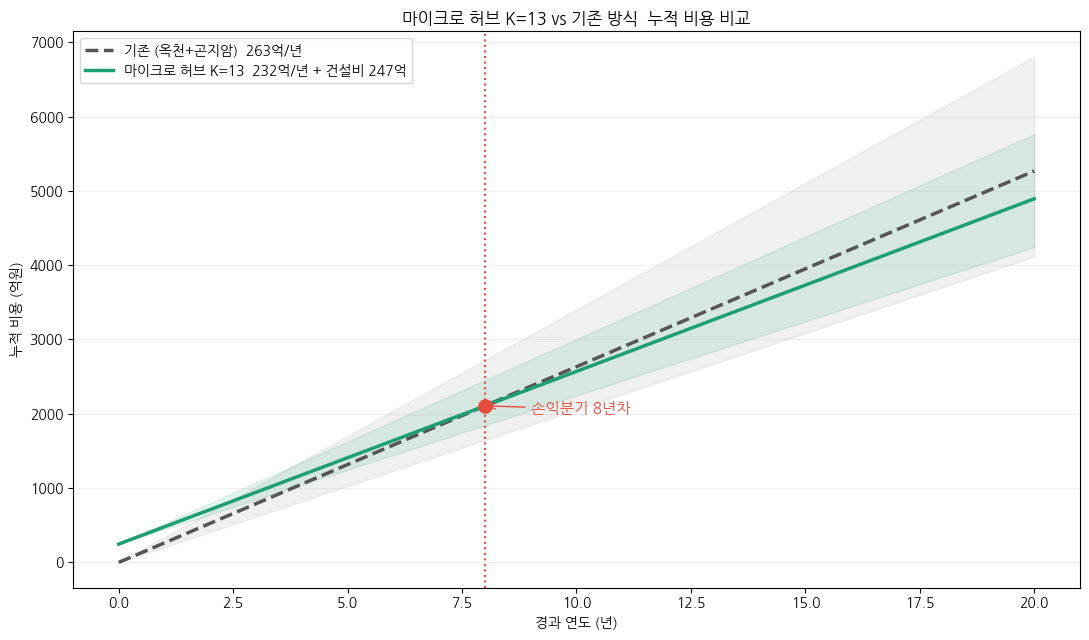

K=13 허브 물동량 지니계수: 0.5815
  하남시              24.7%
  부평구              22.3%
  화성시 동탄구          14.8%
  고양시 일산서구         12.4%
  안산시 상록구          11.6%
  의정부시              8.5%
  평택시               2.4%
  이천시               1.0%
  포천시               0.8%
  안성시               0.7%
  여주시               0.4%
  양평군               0.4%
  가평군               0.2%


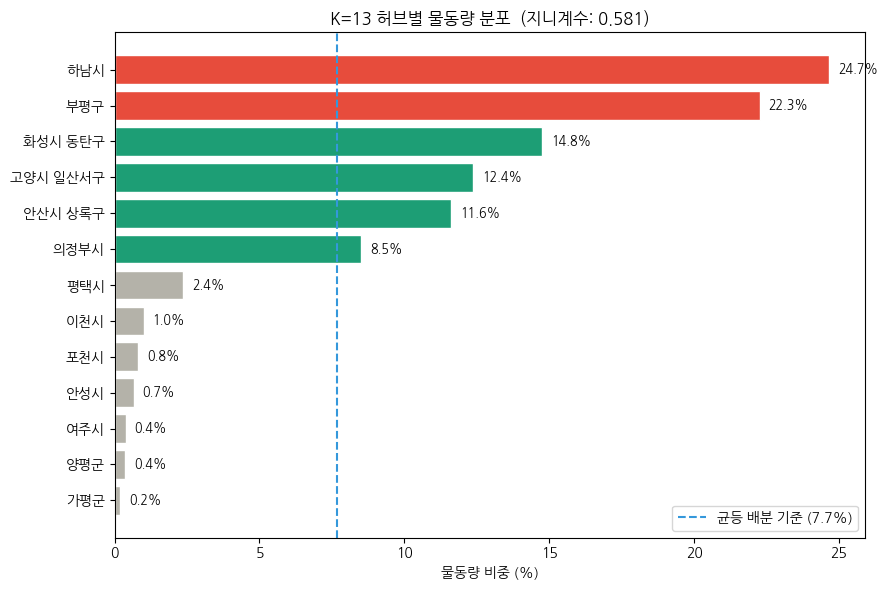

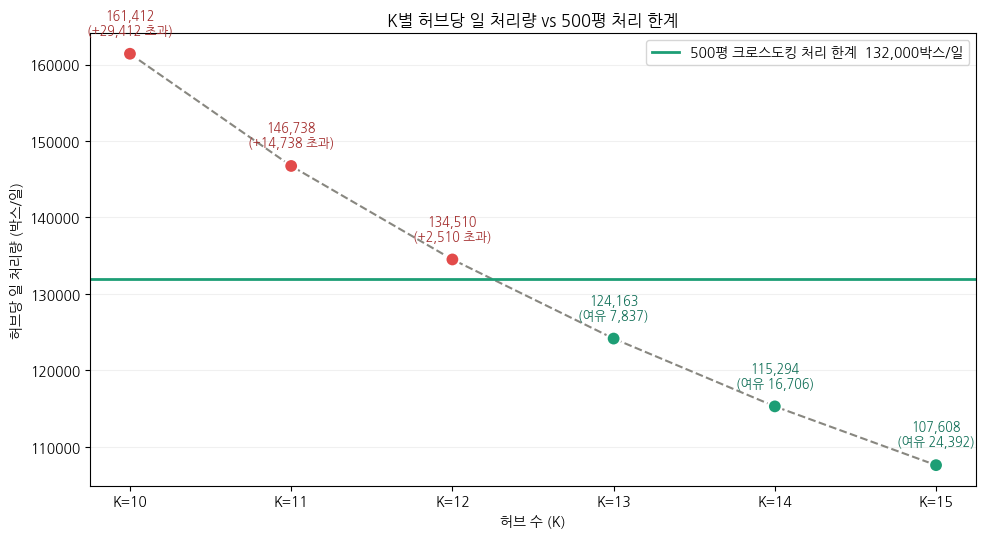

In [14]:
plot_cumulative_cost(K_SELECTED)
print_hub_distribution(K_SELECTED)
plot_hub_distribution(K_SELECTED)
plot_capacity()

## 6. 최종 결과

In [15]:
result_df = pd.DataFrame(
    [
        {
            "K": k,
            "허브당 일처리(박스)": round(MC_RESULTS[k]["daily_per_hub"]),
            "처리가능량(박스/일)": round(264000 - MC_RESULTS[k]["daily_per_hub"]),
            "처리한계132000대비": round(MC_RESULTS[k]["daily_per_hub"] - CAPACITY),
            "처리가능": "가능" if MC_RESULTS[k]["is_ok"] else "초과",
            "연간비용(억)": round(np.median(MC_RESULTS[k]["annual"]), 1),
            "기존대비절감(억)": round(base_median - np.median(MC_RESULTS[k]["annual"]), 1),
            "초기건설비(억)": round(np.median(MC_RESULTS[k]["build"]), 1),
            "손익분기(년)": round(MC_RESULTS[k]["breakeven"]) if MC_RESULTS[k]["breakeven"] else "미달성",
        }
        for k in K_RANGE
    ]
)

save_table(result_df, "비교_최종.csv")
result_df

,K,허브당 일처리(박스),처리가능량(박스/일),처리한계132000대비,처리가능,연간비용(억),기존대비절감(억),초기건설비(억),손익분기(년)
0,10,161412,102588,29412,초과,218.9000,44.4000,190.1000,4
1,11,146738,117262,14738,초과,222.8000,40.6000,209.1000,5
2,12,134510,129490,2510,초과,227.5000,35.9000,228.1000,6
3,13,124163,139837,-7837,가능,232.3000,31.0000,247.1000,8
4,14,115294,148706,-16706,가능,240.1000,23.3000,266.1000,11
5,15,107608,156392,-24392,가능,238.8000,24.5000,285.1000,12
